# 01. Исследовательский анализ данных (EDA) и очистка

**Цель этапа:** понять структуру датасетов RadioML 2016.10a и Panoradio HF, проверить их качество
(баланс, нормировка, дубли, «пустые» примеры, утечка между примерами) и сформулировать решения
для следующих этапов.

**Шаги:**
1. Баланс классов и ОСШ.
2. Как выглядят сигналы: I/Q во времени, созвездия, спектры.
3. Нормировка мощности.
4. Точные дубли.
5. Перекрытие примеров (утечка train/test).
6. «Пустые» примеры AM-DSB / WBFM.
7. Первые признаки: какие классы различимы.
8. Panoradio HF.
9. Выводы и решения.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from amc.radioml import load_npz

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(42)
sns.set_theme(style="whitegrid", context="notebook")


def savefig(name: str) -> None:
    """Сохранить текущий рисунок в reports/figures/eda."""
    plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")


X, y, snr, classes = load_npz(ROOT / "data" / "radioml" / "rml2016a.npz")
z = X[:, 0, :] + 1j * X[:, 1, :]  # комплексный сигнал [N, 128]
print(X.shape, z.dtype, len(classes), "классов")

(220000, 2, 128) complex64 11 классов


## 1. Баланс классов и ОСШ

In [2]:
bal = pd.crosstab(pd.Categorical([classes[i] for i in y], categories=classes), snr)
print("примеров на (класс, ОСШ): min", bal.values.min(), "max", bal.values.max())
bal.iloc[:, ::4]

примеров на (класс, ОСШ): min 1000 max 1000


col_0,-20,-12,-4,4,12
row_0,,,,,
8PSK,1000,1000,1000,1000,1000
AM-DSB,1000,1000,1000,1000,1000
AM-SSB,1000,1000,1000,1000,1000
BPSK,1000,1000,1000,1000,1000
CPFSK,1000,1000,1000,1000,1000
GFSK,1000,1000,1000,1000,1000
PAM4,1000,1000,1000,1000,1000
QAM16,1000,1000,1000,1000,1000
QAM64,1000,1000,1000,1000,1000


Датасет идеально сбалансирован: 1000 примеров на каждую пару (класс, ОСШ), 11 × 20 × 1000 = 220 000.
Значит, accuracy — корректная метрика, а взвешивать классы не нужно.

## 2. Как выглядят сигналы

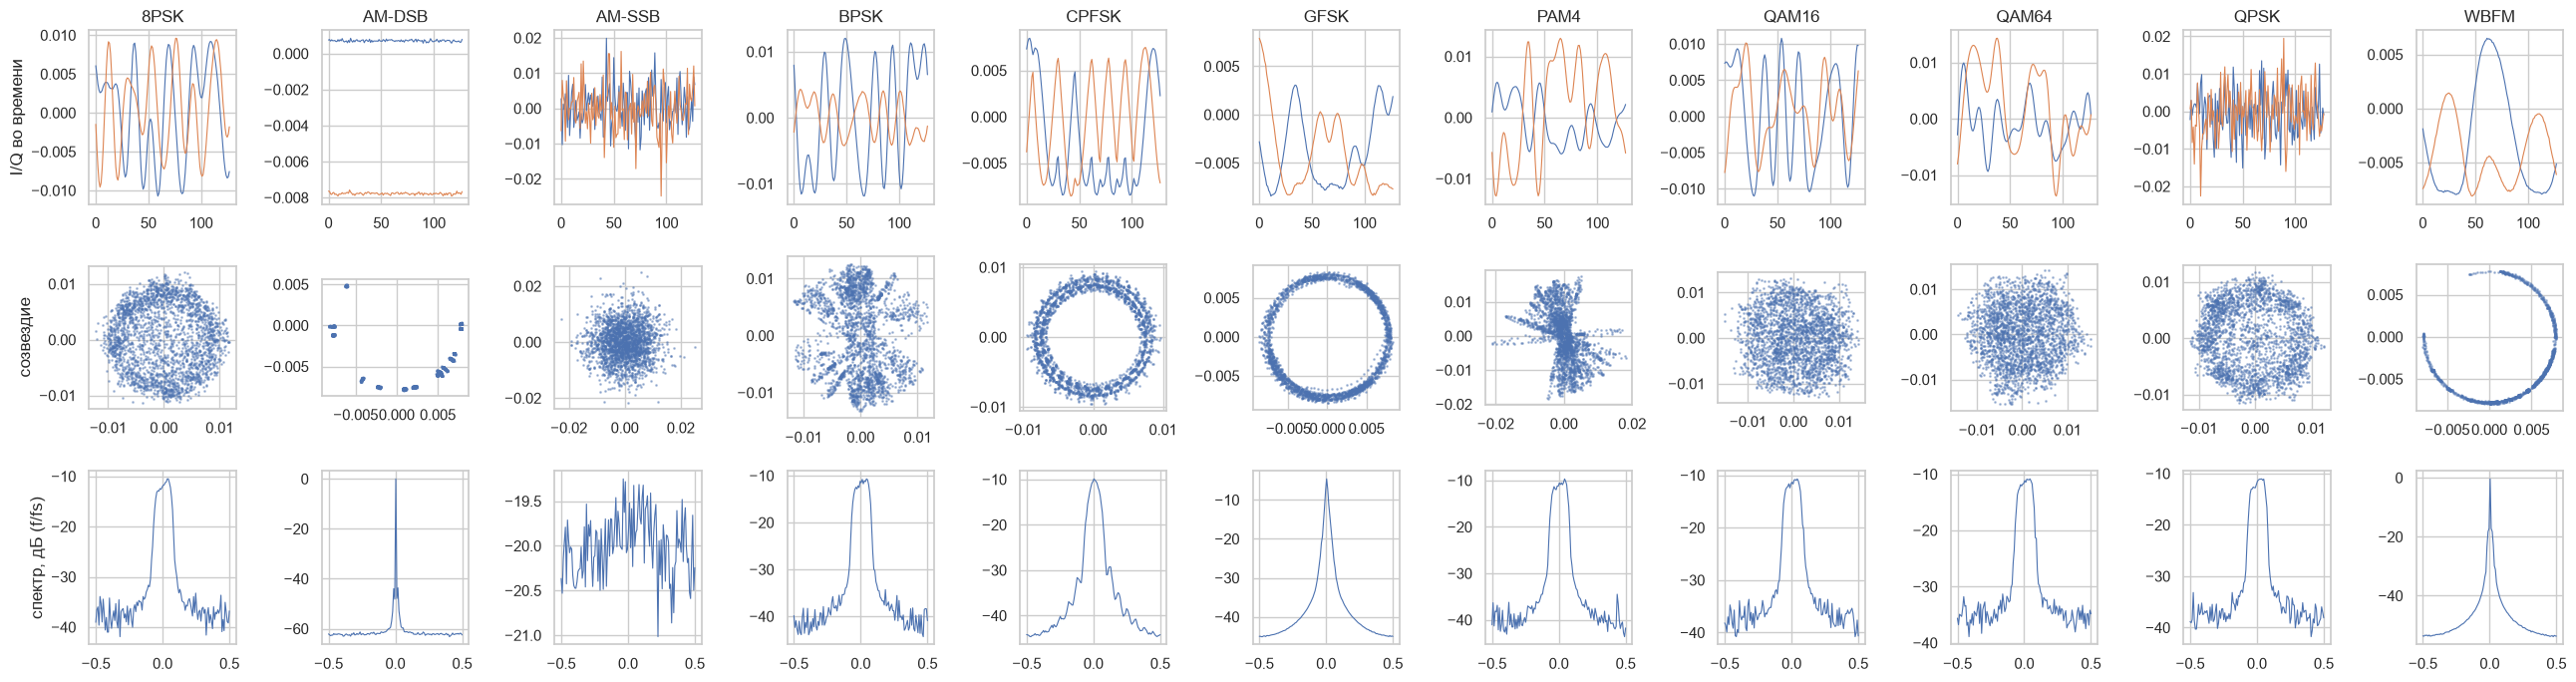

In [3]:
def pick(cls: str, s: int, k: int = 1) -> np.ndarray:
    """Случайные k примеров класса cls при ОСШ s."""
    idx = np.flatnonzero((y == classes.index(cls)) & (snr == s))
    return z[RNG.choice(idx, k, replace=False)]


fig, axes = plt.subplots(3, 11, figsize=(26, 7))
for j, c in enumerate(classes):
    s = pick(c, 18)[0]
    axes[0, j].plot(s.real, lw=0.8)
    axes[0, j].plot(s.imag, lw=0.8)
    axes[0, j].set_title(c)
    pts = pick(c, 18, 20).ravel()
    axes[1, j].scatter(pts.real, pts.imag, s=1, alpha=0.4)
    axes[1, j].set_aspect("equal")
    spec = np.mean(np.abs(np.fft.fftshift(np.fft.fft(pick(c, 18, 200), axis=1), axes=1)) ** 2, axis=0)
    axes[2, j].plot(np.linspace(-0.5, 0.5, 128), 10 * np.log10(spec + 1e-12), lw=0.8)
axes[0, 0].set_ylabel("I/Q во времени")
axes[1, 0].set_ylabel("созвездие")
axes[2, 0].set_ylabel("спектр, дБ (f/fs)")
plt.tight_layout()
savefig("signals_snr18")
plt.show()

**Наблюдения (ОСШ +18 дБ):**
- созвездия ФМн/КАМ «размазаны» по кругу — в данных есть остаточный сдвиг частоты и случайная фаза,
  поэтому сеть должна быть инвариантна к повороту фазы → **аугментация поворотом фазы**;
- QAM16 и QAM64 на 128 отсчётах визуально почти неотличимы — ожидаемая главная пара ошибок;
- AM-DSB и WBFM узкополосные, у части примеров виден почти чистый тон (см. п. 6);
- спектры цифровых классов похожи по ширине → различать их будут статистики высших порядков, а не полоса.

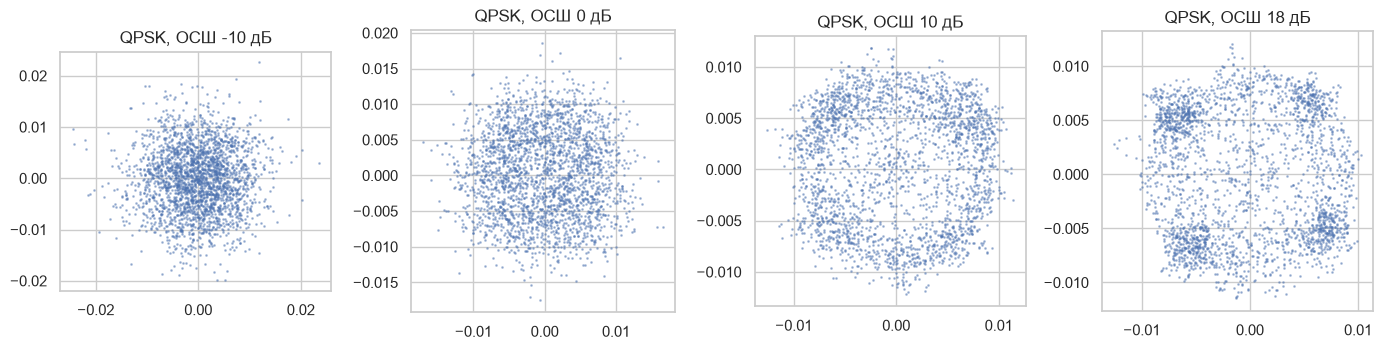

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, s in zip(axes, [-10, 0, 10, 18]):
    pts = pick("QPSK", s, 20).ravel()
    ax.scatter(pts.real, pts.imag, s=1, alpha=0.4)
    ax.set_title(f"QPSK, ОСШ {s} дБ")
    ax.set_aspect("equal")
plt.tight_layout()
savefig("qpsk_vs_snr")
plt.show()

При ОСШ ниже 0 дБ структура созвездия исчезает в шуме — при ОСШ < −10 дБ классификация
принципиально близка к угадыванию; это граница возможного, а не недостаток модели.

## 3. Нормировка мощности

count    220000.000000
mean          0.000073
std           0.000009
min           0.000061
25%           0.000068
50%           0.000075
75%           0.000078
max           0.000647
Name: power, dtype: float64


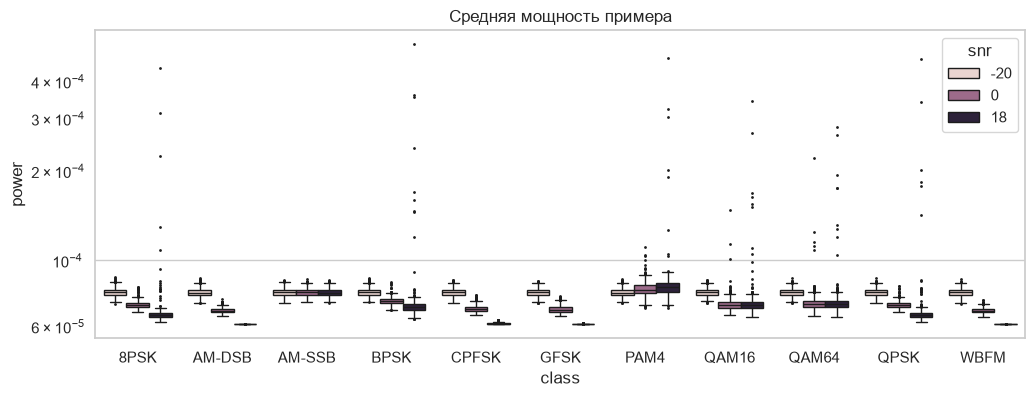

In [5]:
power = np.mean(np.abs(z) ** 2, axis=1)
df = pd.DataFrame({"class": [classes[i] for i in y], "snr": snr, "power": power})
print(df["power"].describe())
plt.figure(figsize=(12, 4))
sns.boxplot(data=df[df.snr.isin([-20, 0, 18])], x="class", y="power", hue="snr", fliersize=1)
plt.yscale("log")
plt.title("Средняя мощность примера")
savefig("power")
plt.show()

Мощность примеров не нормирована строго к 1 и различается по классам → модель может «подсматривать» класс
по мощности, а на реальном сигнале с другим усилением это сломается.
**Решение: нормировать каждый пример на единичную среднюю мощность** перед подачей в модель.

## 4. Точные дубли

In [6]:
h = pd.util.hash_array(np.ascontiguousarray(X.reshape(len(X), -1)).view(f"V{X[0].nbytes}").ravel())
dup = pd.Series(h).duplicated(keep=False)
print("точных дублей:", int(dup.sum()))

точных дублей: 0


## 5. Перекрытие примеров (утечка)

В исходном генераторе RadioML окна по 128 отсчётов вырезаются из одного длинного потока на каждую пару
(класс, ОСШ). Если окна перекрываются, один и тот же кусок сигнала может попасть и в train, и в test.
Проверка: для пар примеров одного класса при ОСШ +18 дБ ищем максимум нормированной взаимной корреляции
по всем сдвигам. Перекрывающиеся окна дадут пик, близкий к доле перекрытия.

In [7]:
def max_xcorr(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    """Максимум |нормированной взаимной корреляции| по сдвигам для пар строк a[i], b[i]."""
    n = a.shape[1]
    fa = np.fft.fft(a, 2 * n, axis=1)
    fb = np.fft.fft(b, 2 * n, axis=1)
    cc = np.abs(np.fft.ifft(fa * np.conj(fb), axis=1))
    norm = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
    return cc.max(axis=1) / norm


rows = []
for c in classes:
    idx = np.flatnonzero((y == classes.index(c)) & (snr == 18))
    sub = z[RNG.choice(idx, 250, replace=False)]
    i, j = np.triu_indices(len(sub), 1)
    m = max_xcorr(sub[i], sub[j])
    rows.append({"class": c, "пар": len(m), "доля > 0.5": np.mean(m > 0.5), "доля > 0.8": np.mean(m > 0.8),
                 "медиана": np.median(m)})
overlap = pd.DataFrame(rows).set_index("class")
overlap

,пар,доля > 0.5,доля > 0.8,медиана
class,,,,
8PSK,31125,0.093269,0.000000,0.398464
AM-DSB,31125,1.000000,1.000000,0.999895
AM-SSB,31125,0.000000,0.000000,0.179078
BPSK,31125,0.328000,0.001446,0.458577
CPFSK,31125,0.284980,0.001896,0.444623
GFSK,31125,0.705542,0.045526,0.570077
PAM4,31125,0.325365,0.000289,0.457954
QAM16,31125,0.082988,0.000000,0.395546
QAM64,31125,0.083470,0.000000,0.398217


Интерпретация — в разделе выводов (зависит от результата: доля пар с высокой корреляцией у цифровых
классов — признак перекрытия окон; у AM-DSB/WBFM высокая корреляция возможна и без перекрытия — чистый тон).

## 6. «Пустые» примеры AM-DSB / WBFM

Источник для аналоговых классов — звук с паузами. В паузе AM-DSB и WBFM вырождаются в чистую несущую.
Мера: доля мощности в самом сильном бине спектра (для чистого тона → 1).

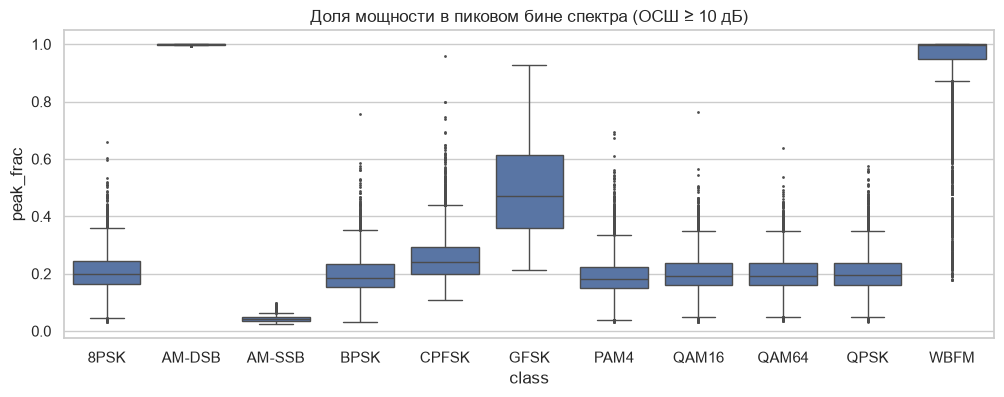

доля примеров «почти чистый тон» (>50 % мощности в одном бине), ОСШ ≥ 10 дБ:
class
8PSK      0.002
AM-DSB    1.000
AM-SSB    0.000
BPSK      0.002
CPFSK     0.014
GFSK      0.446
PAM4      0.003
QAM16     0.001
QAM64     0.001
QPSK      0.002
WBFM      0.948
Name: peak_frac, dtype: float64


In [8]:
spec = np.abs(np.fft.fft(z, axis=1)) ** 2
peak_frac = spec.max(axis=1) / spec.sum(axis=1)
df["peak_frac"] = peak_frac
hi = df[df.snr >= 10]
plt.figure(figsize=(12, 4))
sns.boxplot(data=hi, x="class", y="peak_frac", fliersize=1)
plt.title("Доля мощности в пиковом бине спектра (ОСШ ≥ 10 дБ)")
savefig("peak_frac")
plt.show()
tone = hi.groupby("class")["peak_frac"].apply(lambda v: np.mean(v > 0.5))
print("доля примеров «почти чистый тон» (>50 % мощности в одном бине), ОСШ ≥ 10 дБ:")
print(tone.round(3))

Для AM-DSB доля пика ≈ 1 у всех примеров: у АМ с несущей несущая и так несёт бо́льшую часть мощности,
поэтому эта мера паузы не выделяет. Точнее — **глубина модуляции огибающей** СКО(|z|)/среднее(|z|):
в паузе она падает до уровня шума. Для WBFM пауза = чистый тон (доля пика ≈ 1) — у 95 % примеров.

### 6б. Глубина модуляции и спектральная плоскостность
Спектральная плоскостность (отношение геометрического среднего спектра к арифметическому) для белого
гауссова шума по одной реализации ≈ e^(−γ) ≈ 0,56; для узкополосного сигнала — близка к 0.
Если у класса при ОСШ +18 дБ плоскостность как у шума — в примерах **нет сигнала**.

плоскостность чистого шума: 0.565


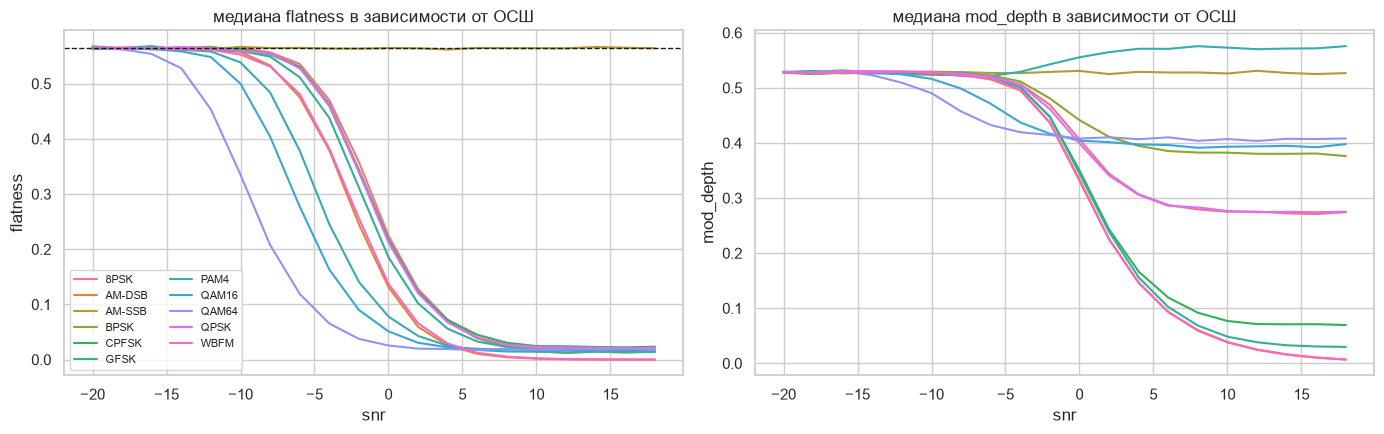

snr,-20,0,10,18
class,,,,
8PSK,0.563,0.225,0.020,0.020
AM-DSB,0.565,0.131,0.002,0.000
AM-SSB,0.563,0.565,0.564,0.564
BPSK,0.563,0.217,0.015,0.015
CPFSK,0.564,0.216,0.025,0.023
GFSK,0.568,0.185,0.017,0.017
PAM4,0.564,0.078,0.014,0.014
QAM16,0.563,0.051,0.018,0.020
QAM64,0.565,0.026,0.017,0.018


In [9]:
env = np.abs(z)
df["mod_depth"] = env.std(axis=1) / env.mean(axis=1)
psd = spec + 1e-20
df["flatness"] = np.exp(np.mean(np.log(psd), axis=1)) / np.mean(psd, axis=1)
noise = (RNG.standard_normal((5000, 128)) + 1j * RNG.standard_normal((5000, 128))) / np.sqrt(2)
pn = np.abs(np.fft.fft(noise, axis=1)) ** 2
noise_flat = float(np.mean(np.exp(np.mean(np.log(pn), axis=1)) / np.mean(pn, axis=1)))
print(f"плоскостность чистого шума: {noise_flat:.3f}")

gf = df.groupby(["class", "snr"])[["mod_depth", "flatness"]].median().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ["flatness", "mod_depth"]):
    sns.lineplot(data=gf, x="snr", y=col, hue="class", ax=ax, legend=(col == "flatness"))
    ax.set_title(f"медиана {col} в зависимости от ОСШ")
axes[0].axhline(noise_flat, ls="--", c="k", lw=1)
axes[0].legend(ncol=2, fontsize=8)
plt.tight_layout()
savefig("flatness_depth")
plt.show()
flat_tbl = gf.pivot(index="class", columns="snr", values="flatness")[[-20, 0, 10, 18]].round(3)
flat_tbl

In [10]:
am = df[(df["class"] == "AM-DSB") & (df.snr >= 10)]
print("AM-DSB, ОСШ ≥ 10: глубина модуляции, квантили 10/50/90 %:",
      np.round(np.percentile(am["mod_depth"], [10, 50, 90]), 4))

AM-DSB, ОСШ ≥ 10: глубина модуляции, квантили 10/50/90 %: [0.0069 0.0182 0.0395]


## 7. Первые признаки: различимость классов

Нормированный кумулянт C42 — классический признак для цифровых модуляций (теоретически: BPSK −2,
QPSK −1, 8PSK −1, QAM16 −0,68, QAM64 −0,62, гауссов шум 0).

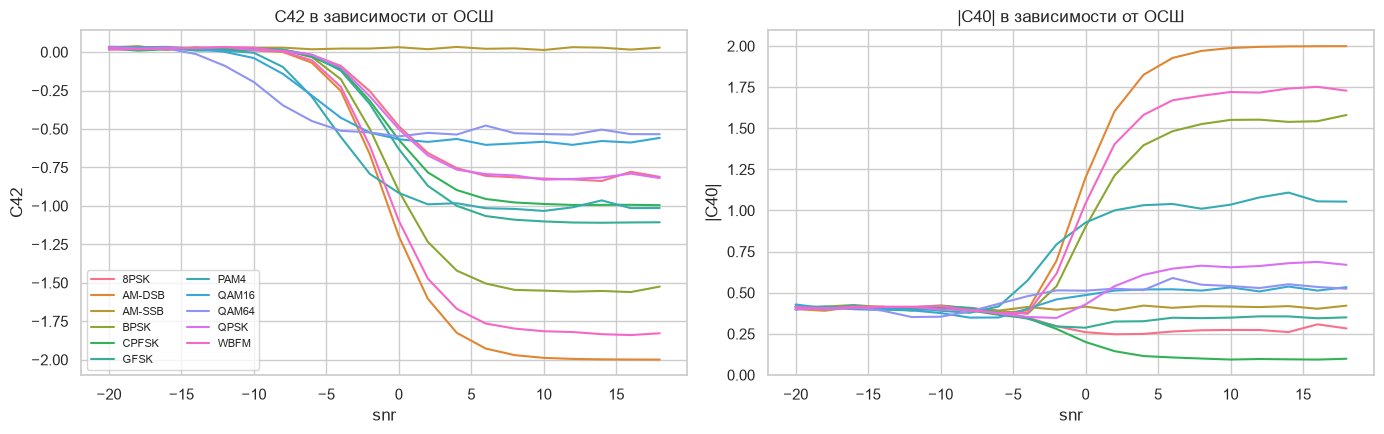

In [11]:
zn = z / np.sqrt(power[:, None])
c20 = np.mean(zn**2, axis=1)
c21 = np.mean(np.abs(zn) ** 2, axis=1)
c40 = np.mean(zn**4, axis=1) - 3 * c20**2
c42 = np.mean(np.abs(zn) ** 4, axis=1) - np.abs(c20) ** 2 - 2 * c21**2
df["|C40|"] = np.abs(c40)
df["C42"] = c42.real
g = df.groupby(["class", "snr"])[["C42", "|C40|"]].mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ["C42", "|C40|"]):
    sns.lineplot(data=g, x="snr", y=col, hue="class", ax=ax, legend=(col == "C42"))
    ax.set_title(f"{col} в зависимости от ОСШ")
axes[0].legend(ncol=2, fontsize=8)
plt.tight_layout()
savefig("cumulants")
plt.show()

Кумулянты разводят группы модуляций при высоком ОСШ и сходятся к 0 (гауссов шум) при низком —
признаки информативны, но их средние у близких классов (QAM16/QAM64, QPSK/8PSK) близки →
одних кумулянтов мало, нужны модели, видящие структуру сигнала целиком.

## 8. Panoradio HF

In [12]:
PAN = ROOT / "data" / "external" / "panoradio_hf"
tags = pd.read_csv(PAN / "dataset_panoradio_hf_tags.csv", skipinitialspace=True)
pan = np.load(PAN / "dataset_panoradio_hf.npy", mmap_mode="r", allow_pickle=False)
print(pan.shape, pan.dtype)
print(pd.crosstab(tags["mode"], tags["snr"]).iloc[:, :].head(18))

(172800, 2048) complex128
snr             -10   -5     0     5     10    15    20    25
mode                                                         
am             1200  1200  1200  1200  1200  1200  1200  1200
dominoex11     1200  1200  1200  1200  1200  1200  1200  1200
fax            1200  1200  1200  1200  1200  1200  1200  1200
lsb            1200  1200  1200  1200  1200  1200  1200  1200
morse          1200  1200  1200  1200  1200  1200  1200  1200
mt63_1000      1200  1200  1200  1200  1200  1200  1200  1200
navtex         1200  1200  1200  1200  1200  1200  1200  1200
olivia16_1000  1200  1200  1200  1200  1200  1200  1200  1200
olivia16_500   1200  1200  1200  1200  1200  1200  1200  1200
olivia32_1000  1200  1200  1200  1200  1200  1200  1200  1200
olivia8_250    1200  1200  1200  1200  1200  1200  1200  1200
psk31          1200  1200  1200  1200  1200  1200  1200  1200
psk63          1200  1200  1200  1200  1200  1200  1200  1200
qpsk31         1200  1200  1200  1200  1200 

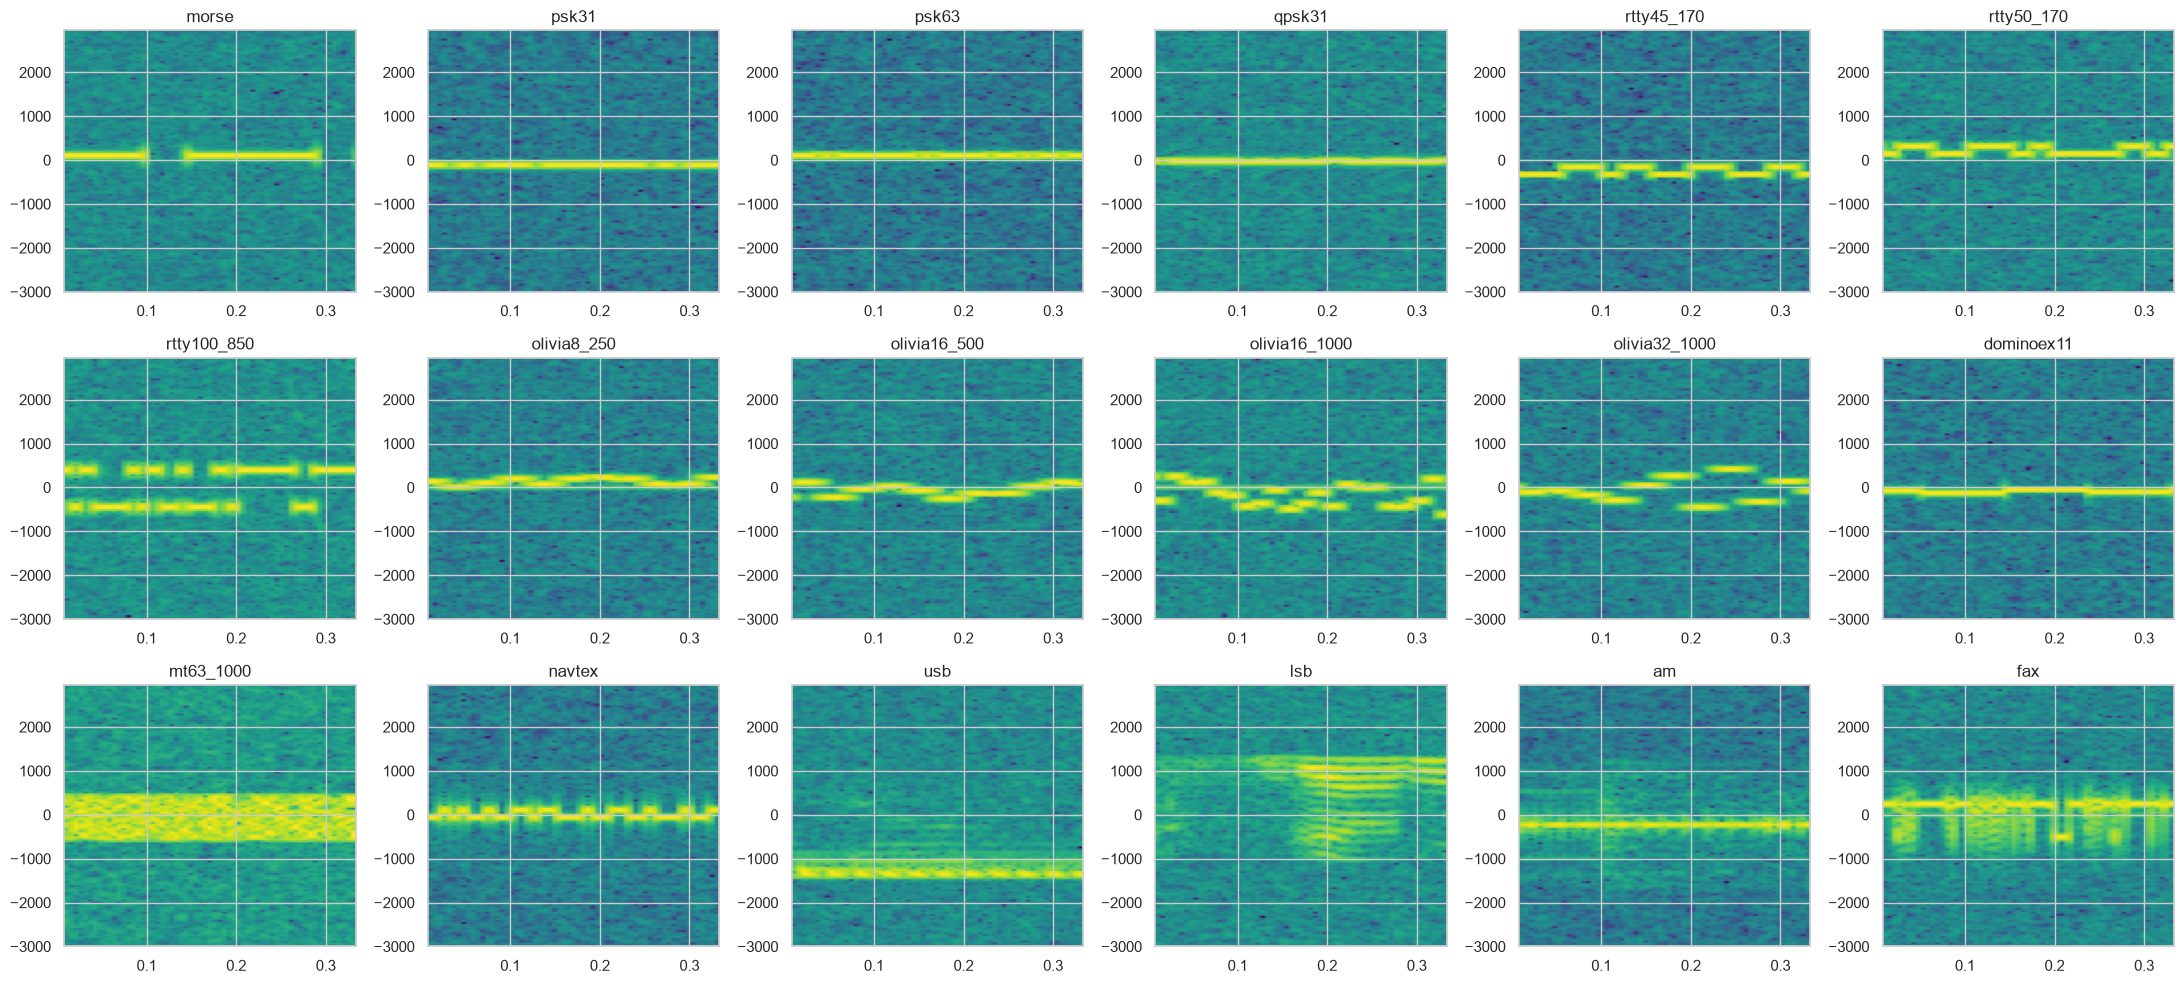

In [13]:
modes = list(tags["mode"].unique())
fig, axes = plt.subplots(3, 6, figsize=(22, 10))
for ax, m in zip(axes.ravel(), modes):
    i = int(tags.index[(tags["mode"] == m) & (tags["snr"] == 25)][0])
    ax.specgram(np.asarray(pan[i]), NFFT=128, Fs=6000, noverlap=96, cmap="viridis")
    ax.set_title(m)
plt.tight_layout()
savefig("panoradio_specgrams")
plt.show()

In [14]:
pw = np.mean(np.abs(np.asarray(pan[RNG.choice(len(pan), 2000, replace=False)])) ** 2, axis=1)
print("мощность примеров Panoradio: среднее %.3f, СКО %.3f" % (pw.mean(), pw.std()))

мощность примеров Panoradio: среднее 1.000, СКО 0.000


## 9. Выводы и решения для следующих этапов

| № | Наблюдение | Доказательство | Решение |
|---|---|---|---|
| 1 | Баланс идеальный: 1000 примеров на (класс, ОСШ); Panoradio — 1200 на (режим, ОСШ) | п. 1, 8 | accuracy — корректная метрика, веса классов не нужны; разбиение стратифицировать по (класс × ОСШ) |
| 2 | Точных дублей нет | п. 4 | удалять нечего |
| 3 | **Перекрытия окон у цифровых классов практически нет** (пар с корреляцией > 0,8 — 0,03 %) | п. 5 | случайное стратифицированное разбиение допустимо; высокая корреляция AM-DSB/WBFM — из-за чистого тона, а не перекрытия |
| 4 | Мощность RadioML ≈ 7·10⁻⁵, не нормирована, есть выбросы до ×10; Panoradio нормирован к 1 | п. 3 | **нормировать каждый пример на единичную мощность** (иначе модель учит уровень, а не модуляцию) |
| 5 | **AM-SSB в RadioML 2016.10a — чистый шум при любом ОСШ** (плоскостность 0,564 = шум 0,565) | п. 6б | дефект датасета: класс фактически «шум». Для сравнения с литературой оставляем, но отчитываемся и метриками без AM-SSB; настоящий AM-SSB — из своего генератора |
| 6 | AM-DSB — почти немодулированная несущая (глубина ≈ 2 %), WBFM — чистый тон в 95 % примеров | п. 6 | пара AM-DSB↔WBFM принципиально трудно различима на 128 отсчётах — ожидаемая ошибка, учитывать при анализе |
| 7 | Созвездия «размазаны» — случайная фаза и остаточный сдвиг частоты | п. 2 | аугментации: поворот фазы, малый сдвиг частоты; модели, инвариантные к фазе |
| 8 | Кумулянты C42, C40 разводят группы модуляций при ОСШ > 0 дБ, сходятся к 0 при низком ОСШ | п. 7 | взять кумулянты в baseline; QAM16/QAM64 и QPSK/8PSK ими плохо разделяются |
| 9 | При ОСШ < −10 дБ все классы неотличимы от шума (плоскостность = шум) | п. 2, 6б | точность ≈ 9 % при низком ОСШ — предел данных; основную метрику считать и отдельно для ОСШ ≥ 0 |
| 10 | Panoradio HF: 18 режимов × 8 ОСШ, 2048 отсчётов при 6 кГц, спектрограммы режимов различимы глазом при высоком ОСШ | п. 8 | КВ-расширение: окна 2048, сеть со спектрограммным или 1D-входом |

**Итог этапа:** данные пригодны для обучения после нормировки мощности; выявлен дефект класса AM-SSB
и принципиальная неразличимость AM-DSB/WBFM, которые надо учитывать при оценке моделей.

In [15]:
summary = {
    "точных дублей RadioML": int(dup.sum()),
    "мощность RadioML: мин/медиана/макс": (float(power.min()), float(np.median(power)), float(power.max())),
    "доля пар с перекрытием >0.8 (цифровые, ОСШ 18)": float(
        overlap.loc[["BPSK", "QPSK", "8PSK", "QAM16", "QAM64", "PAM4"], "доля > 0.8"].mean()),
    "доля тонов AM-DSB (ОСШ≥10)": float(tone["AM-DSB"]),
    "доля тонов WBFM (ОСШ≥10)": float(tone["WBFM"]),
}
for k, v in summary.items():
    print(f"{k}: {v}")

точных дублей RadioML: 0
мощность RadioML: мин/медиана/макс: (6.103645137045532e-05, 7.512008596677333e-05, 0.0006465911865234375)
доля пар с перекрытием >0.8 (цифровые, ОСШ 18): 0.00028915662650602414
доля тонов AM-DSB (ОСШ≥10): 1.0
доля тонов WBFM (ОСШ≥10): 0.948
